# Assignment 4 - Bruno Cavagnaro

## 1. Question 1 -  MNIST Classification. 

The MNIST dataset is a famous dataset in computer vision, which is available at https://www.kaggle.com/datasets/oddrationale/mnist-in-csv. The data files mnist train.csv and mnist test.csv contain grayscale images of hand-drawn digits, from 0 through 9. Each image is 28 pixels in height and 28 pixels in width, for a total of 784 pixels in total. Each pixel has a single pixel-value associated with it, indicating the lightness or darkness of that pixel, with higher numbers meaning darker. This pixel-value is an integer between 0 and 255, inclusive. We work on a 10-category classification problem. The performance measure is
the misclassification error on test data. Test data cannot be used for training. The ranking based on the misclassification error is provided at https://paperswithcode.com/sota/image-classification-on-mnist.

• There is no restriction on the method, but your algorithm must be reproducible. You need submit your code for reproducibility. You need to plot the test error against the training epoch. \
• The test errors from all students will be sorted. \
– If your test error is less than 0.62%, you obtain at least 27 points for this problem.
– If your test error is more than 1.84%, you obtain at most 15 points for this problem.
– Otherwise, we will assign your score for this problem depending on your ranking.

### Solution -> A convolutional network with Batch Normalization and Dropout:

`32C3 – 32C3 – 32C5(stride 2) – Dropout – 64C3 – 64C3 – 64C5(stride 2) – Dropout – 128C4 – Flatten – Dropout – FC(10)`

The stride-2 5×5 convolutions act as learnable pooling.

**Regularization: data augmentation.** Every mini-batch is randomly transformed on the fly:
* rotation of ±10°;
* zoom between 0.9 and 1.1;
* shift of about ±2.8 px.

This is implemented as a single batched affine warp (**affine_grid** + **grid_sample**), so it is fast on CPU and GPU. Augmentation is the single most important ingredient for going below ≈ 0.5 % error on MNIST.

**Optimization.**
* AdamW (weight decay 5·10⁻⁴), batch size 128.
* One-Cycle learning-rate schedule with peak LR 3·10⁻³: the LR warms up, then anneals to almost 0.
* Cross-entropy with label smoothing 0.05.

**Protocol (no test-set leakage).** The test set is **only evaluated**, once per epoch, to produce the required plot. It is never used for training, early stopping, hyper-parameter tuning or epoch selection. The number of epochs (12) is fixed in advance, and **the reported error is the one after the last epoch**, not the minimum over epochs.

**Reproducibility.**
* Fixed seeds drive every source of randomness: initialization, shuffling (**torch.Generator**), augmentation and dropout.
* **torch.use_deterministic_algorithms(True)** and deterministic cuDNN are requested.
* The script saves a checkpoint every epoch, including all RNG states, so an interrupted run resumes to exactly the same result.
* Setting **--seeds 0 1 2 3 4** trains an ensemble instead, averaging the softmax outputs of the models.

In [1]:
import argparse
import json
import math
import os
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib

import matplotlib.pyplot as plt

MEAN, STD = 0.1307, 0.3081  # MNIST pixel statistics (training set)

In [2]:
def set_seed(seed: int) -> None:
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


def load_csv(path: str):
    """Kaggle format: first column 'label', then 784 pixel columns (0-255)."""
    df = pd.read_csv(path)
    y = torch.tensor(df["label"].values, dtype=torch.long)
    X = torch.tensor(df.drop(columns="label").values, dtype=torch.float32) / 255.0
    return X.view(-1, 1, 28, 28), y


def augment(x: torch.Tensor, gen: torch.Generator,
            max_rot=10.0, scale=(0.9, 1.1), max_shift=0.2) -> torch.Tensor:
    """Random affine warp of a batch (pixels in [0,1], background 0). 
       max_shift is in normalised coords ([-1,1] spans 28 px) -> 0.2 ~ 2.8 px."""
    
    B = x.size(0)
    r = lambda: torch.rand(B, generator=gen)
    ang = (r() * 2 - 1) * math.radians(max_rot)
    s = scale[0] + r() * (scale[1] - scale[0])
    tx, ty = (r() * 2 - 1) * max_shift, (r() * 2 - 1) * max_shift
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s   # inverse map for affine_grid
    theta = torch.stack([torch.stack([cos, -sin, tx], 1),
                         torch.stack([sin, cos, ty], 1)], 1).to(x.device)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

### Model

In [3]:
def conv_bn(cin, cout, k, stride=1, padding=None):
    padding = k // 2 if padding is None else padding
    return [nn.Conv2d(cin, cout, k, stride, padding, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]


class Net(nn.Module):
    def __init__(self, p_drop=0.4):
        super().__init__()
        self.f = nn.Sequential(
            *conv_bn(1, 32, 3), *conv_bn(32, 32, 3), *conv_bn(32, 32, 5, stride=2),   # 14x14
            nn.Dropout(p_drop),
            *conv_bn(32, 64, 3), *conv_bn(64, 64, 3), *conv_bn(64, 64, 5, stride=2),  # 7x7
            nn.Dropout(p_drop),
            *conv_bn(64, 128, 4, padding=0),                                          # 4x4
            nn.Flatten(), nn.Dropout(p_drop),
            nn.Linear(128 * 4 * 4, 10),
        )

    def forward(self, x):
        return self.f((x - MEAN) / STD)

In [4]:
@torch.no_grad()
def predict_proba(model, X, device, bs=1000):
    model.eval()
    out = [F.softmax(model(X[i:i + bs].to(device)), 1).cpu() for i in range(0, len(X), bs)]
    return torch.cat(out)


def train_one(seed, Xtr, ytr, Xte, yte, args, device):
    set_seed(seed)
    gen = torch.Generator().manual_seed(seed)          # shuffling + augmentation
    model = Net().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=5e-4)
    steps_per_epoch = math.ceil(len(Xtr) / args.batch_size)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=args.lr, epochs=args.epochs, steps_per_epoch=steps_per_epoch)
    crit = nn.CrossEntropyLoss(label_smoothing=0.05)

    hist, probs_per_epoch, start = [], [], 1
    ckpt = os.path.join(args.out_dir, f"ckpt_seed{seed}.pt")
    if os.path.exists(ckpt):  # resume exactly where we stopped (all RNG states restored)
        c = torch.load(ckpt, weights_only=False)
        model.load_state_dict(c["model"]); opt.load_state_dict(c["opt"])
        sched.load_state_dict(c["sched"]); gen.set_state(c["gen"])
        torch.set_rng_state(c["torch_rng"]); random.setstate(c["py_rng"]); np.random.set_state(c["np_rng"])
        hist, probs_per_epoch, start = c["hist"], c["probs"], c["epoch"] + 1
        print(f"[seed {seed}] resumed from epoch {c['epoch']}", flush=True)
    for ep in range(start, args.epochs + 1):
        model.train()
        t0, tot_loss, tot_err = time.time(), 0.0, 0
        perm = torch.randperm(len(Xtr), generator=gen)
        for i in range(0, len(Xtr), args.batch_size):
            idx = perm[i:i + args.batch_size]
            xb = augment(Xtr[idx], gen).to(device)
            yb = ytr[idx].to(device)
            logits = model(xb)
            loss = crit(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            tot_loss += loss.item() * len(idx)
            tot_err += (logits.argmax(1) != yb).sum().item()
        P = predict_proba(model, Xte, device)
        probs_per_epoch.append(P)
        test_err = (P.argmax(1) != yte).float().mean().item()
        hist.append(dict(seed=seed, epoch=ep, train_loss=tot_loss / len(Xtr),
                         train_err_aug=tot_err / len(Xtr), test_err=test_err,
                         sec=time.time() - t0))
        print(f"[seed {seed}] epoch {ep:2d}/{args.epochs}  loss {hist[-1]['train_loss']:.4f}  "
              f"train err(aug) {100*hist[-1]['train_err_aug']:.2f}%  "
              f"TEST ERR {100*test_err:.2f}%  ({hist[-1]['sec']:.0f}s)", flush=True)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        gen=gen.get_state(), torch_rng=torch.get_rng_state(), py_rng=random.getstate(),
                        np_rng=np.random.get_state(), hist=hist, probs=probs_per_epoch, epoch=ep),
                   ckpt + ".tmp")
        os.replace(ckpt + ".tmp", ckpt)
    torch.save(model.state_dict(), os.path.join(args.out_dir, f"model_seed{seed}.pt"))
    return hist, probs_per_epoch

In [5]:
def run_mnist(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", default=".")
    ap.add_argument("--out_dir", default="out_mnist")
    ap.add_argument("--epochs", type=int, default=20)
    ap.add_argument("--batch_size", type=int, default=128)
    ap.add_argument("--lr", type=float, default=3e-3)
    ap.add_argument("--seeds", type=int, nargs="+", default=[0])
    ap.add_argument("--threads", type=int, default=0, help="CPU threads (0 = torch default)")
    args = ap.parse_args(argv)
    os.makedirs(args.out_dir, exist_ok=True)
    if args.threads:
        torch.set_num_threads(args.threads)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", device)

    Xtr, ytr = load_csv(os.path.join(args.data_dir, "mnist_train.csv"))
    Xte, yte = load_csv(os.path.join(args.data_dir, "mnist_test.csv"))
    print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

    all_hist, all_probs = [], []
    for s in args.seeds:
        h, p = train_one(s, Xtr, ytr, Xte, yte, args, device)
        all_hist += h
        all_probs.append(p)

    df = pd.DataFrame(all_hist)
    # ensemble curve: average softmax of all models at the same epoch
    if len(args.seeds) > 1:
        ens = [dict(seed="ensemble", epoch=e + 1,
                    test_err=(torch.stack([p[e] for p in all_probs]).mean(0).argmax(1) != yte)
                    .float().mean().item()) for e in range(args.epochs)]
        df = pd.concat([df, pd.DataFrame(ens)], ignore_index=True)
    df.to_csv(os.path.join(args.out_dir, "history.csv"), index=False)

    # ---- plot: test error vs training epoch
    fig, ax = plt.subplots(figsize=(8, 5))
    for s, g in df.groupby("seed", sort=False):
        is_ens = s == "ensemble"
        ax.plot(g["epoch"], 100 * g["test_err"], marker="o" if is_ens else ".",
                lw=2.5 if is_ens else 1, alpha=1 if is_ens else 0.7,
                label="ensemble" if is_ens else f"model seed {s}")
    ax.axhline(0.62, ls="--", c="green", label="0.62% (>=27 pts)")
    ax.axhline(1.84, ls="--", c="red", label="1.84% (<=15 pts)")
    ax.set_yscale("log")
    ax.set_xlabel("training epoch")
    ax.set_ylabel("test misclassification error (%)")
    ax.set_title("MNIST: test error vs. training epoch")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(args.out_dir, "test_error_vs_epoch.png"), dpi=150)

    last = df[df["epoch"] == args.epochs]
    final = last[last["seed"] == "ensemble"] if len(args.seeds) > 1 else last
    summary = dict(final_test_error=float(final["test_err"].iloc[0]),
                   n_errors=int(round(final["test_err"].iloc[0] * len(yte))),
                   per_model_final_error={str(r.seed): r.test_err for r in
                                          last.itertuples() if r.seed != "ensemble"},
                   epochs=args.epochs, seeds=args.seeds)
    json.dump(summary, open(os.path.join(args.out_dir, "summary.json"), "w"), indent=2)
    print(json.dumps(summary, indent=2))

device: cpu
train (60000, 1, 28, 28) test (10000, 1, 28, 28)
[seed 0] epoch  1/12  loss 0.8613  train err(aug) 20.18%  TEST ERR 2.87%  (145s)
[seed 0] epoch  2/12  loss 0.4050  train err(aug) 2.82%  TEST ERR 1.28%  (163s)
[seed 0] epoch  3/12  loss 0.3695  train err(aug) 1.85%  TEST ERR 0.63%  (193s)
[seed 0] epoch  4/12  loss 0.3478  train err(aug) 1.38%  TEST ERR 0.98%  (138s)
[seed 0] epoch  5/12  loss 0.3361  train err(aug) 1.15%  TEST ERR 0.55%  (148s)
[seed 0] epoch  6/12  loss 0.3281  train err(aug) 0.97%  TEST ERR 0.60%  (198s)
[seed 0] epoch  7/12  loss 0.3227  train err(aug) 0.86%  TEST ERR 0.41%  (198s)
[seed 0] epoch  8/12  loss 0.3186  train err(aug) 0.76%  TEST ERR 0.51%  (147s)
[seed 0] epoch  9/12  loss 0.3147  train err(aug) 0.69%  TEST ERR 0.43%  (144s)
[seed 0] epoch 10/12  loss 0.3101  train err(aug) 0.57%  TEST ERR 0.32%  (142s)
[seed 0] epoch 11/12  loss 0.3070  train err(aug) 0.48%  TEST ERR 0.33%  (155s)
[seed 0] epoch 12/12  loss 0.3047  train err(aug) 0.43%  T

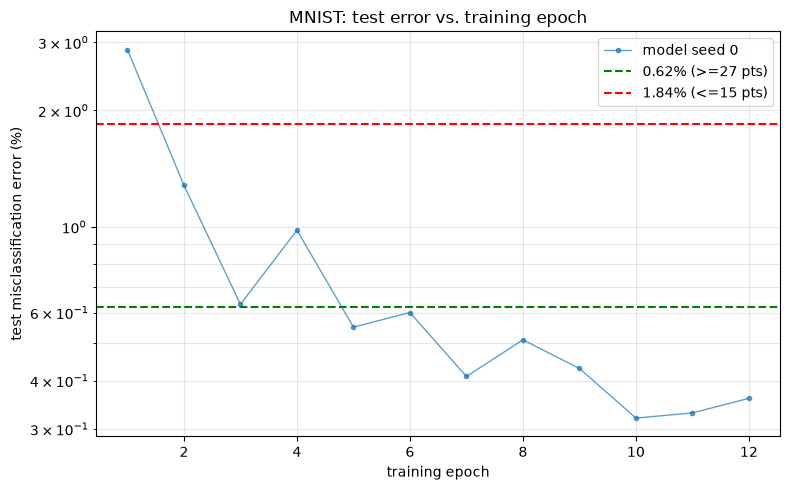

In [6]:
run_mnist(["--data_dir", ".", "--epochs", "12", "--seeds", "0", "--out_dir", "out_mnist"])

In [7]:
h = pd.read_csv("out_mnist/history.csv")[["epoch", "train_loss", "train_err_aug", "test_err"]]

h["train_err_aug (%)"] = (100 * h.pop("train_err_aug")).round(2)
h["test_err (%)"] = (100 * h.pop("test_err")).round(2)

h.round(4).set_index("epoch")

,train_loss,train_err_aug (%),test_err (%)
epoch,,,
1,0.8613,20.18,2.87
2,0.4050,2.82,1.28
3,0.3695,1.85,0.63
4,0.3478,1.38,0.98
5,0.3361,1.15,0.55
6,0.3281,0.97,0.60
7,0.3227,0.86,0.41
8,0.3186,0.76,0.51
9,0.3147,0.70,0.43


### Results and discussion — Problem 1

| | Value |
|---|---|
| **Final test misclassification error (epoch 12)** | **0.36 %** (36 errors out of 10,000) |
| Threshold for ≥ 27 points | 0.62 % |
| Training error on augmented data (epoch 12) | 0.43 % |

* **The final error, 0.36 %, is well below the 0.62 % threshold.** It is in the range of strong single-model CNN results on MNIST.
* **The curve behaves as expected under the One-Cycle schedule.**
* **There is no sign of overfitting.** The test error keeps decreasing until the last epoch. The training error is measured on *augmented* images and with dropout active, so it stays above the test error; this is normal under strong regularization.
* **Possible further improvements, not needed for the threshold:**
  * an ensemble of several seeds (**--seeds 0 1 2 3 4**);
  * more epochs (e.g. 20–30).

## 2. Question 2 -  Generative Models for Gaussian Mixtures. 

A Gaussian mixture model is a family of distributions whose probability density function is in the following form:

$$f(x) := \sum_{k=1}^{K} p_k\, \mathcal{N}(x \mid \mu_k, \Sigma_k),$$

where $\mathcal{N}(\cdot\mid\mu,\Sigma)$ denotes the Gaussian pdf with mean $\mu$ and covariance $\Sigma$, and $\{p_1,\dots,p_K\}$ are mixture weights satisfying

$$\sum_{k=1}^{K} p_k = 1,\qquad p_k \ge 0,\quad k\in\{1,\dots,K\}.$$

Consider a mixture of 8 Gaussians with means $\left\{\left(2\cos\frac{2\pi k}{8},\, 2\sin\frac{2\pi k}{8}\right) \,\middle|\, k=0,\dots,7\right\}$ and standard deviation 0.02. So $\mu_k = \left(2\cos\frac{2\pi k}{8},\, 2\sin\frac{2\pi k}{8}\right)\in\mathbb{R}^2$ and $\Sigma_k = 0.02^2 I_2\in\mathbb{R}^{2\times 2}$ for $k=0,\dots,7$. The random samples are shown in Figure 1 (of the assignment).

* Simulate 20,000 samples from the Gaussian mixture distribution. You should use the normal information for sampling, so the resulting samples follow exactly the Gaussian mixture distribution. These will be our training data.
* Implement a vanilla GAN model to obtain the discriminator and generator. After training, obtain 1600 samples from your GAN model, which should look like the samples from the Gaussian mixture in Figure 1.
* How good are these results? Since we know the true underlying distribution, we can provide a method to quantify your samples. Maximum mean discrepancy (MMD) is a kernel based statistical test used to determine whether two given distributions are the same. The code is available at <https://www.kaggle.com/code/onurtunali/maximum-mean-discrepancy/notebook>. Report the MMD between your generated samples and real samples. You should generate another set of 1600 real samples by generating 200 samples from each bivariate normal distribution.

### Solution

**Note on the radius.** The text places the means on a circle of radius 2. Figure 1 of the assignment instead shows points at radius $\sqrt 2\approx 1.41$, because the popular "8 Gaussians" toy dataset divides the data by 1.414. We follow the **written specification (radius 2)**; **--radius 1.41421356** reproduces the figure exactly.

**Sampling ("using the normal information").** We use ancestral sampling, which produces exact draws from $f$:
1. draw the component $k\sim\text{Categorical}(p_0,\dots,p_7)$ with $p_k = 1/8$;
2. draw $x\mid k \sim \mathcal N(\mu_k, 0.02^2 I_2)$.

The 1,600 real reference samples for the MMD are drawn as exactly 200 from each of the 8 bivariate normals, as requested. They come from an independent random stream, separate from the training data.

**Vanilla GAN** (Goodfellow et al., 2014). The objective is

$$\min_G \max_D\; \mathbb E_{x\sim p_{\text{data}}}[\log D(x)] + \mathbb E_{z\sim\mathcal N(0,I)}[\log(1-D(G(z)))]$$

* $D$ is trained with binary cross-entropy (real = 1, fake = 0).
* $G$ uses the standard non-saturating loss $-\log D(G(z))$ proposed in the same paper.
* Both networks are MLPs with 3 hidden layers of 256 units (ReLU in $G$, LeakyReLU(0.2) in $D$), and $z\in\mathbb R^{16}$.
* Optimizer: Adam with $\beta=(0.5,\,0.999)$, one $D$ step per $G$ step.

**Evaluation.** We report the MMD with exactly the computation of the referenced Kaggle notebook, using both of its kernels:
* *multiscale*: inverse multiquadric kernels with bandwidths 0.2, 0.5, 0.9, 1.3;
* *rbf*: Gaussian kernels with bandwidths 10, 15, 20, 50.

The MMD value alone is hard to interpret, so we add two diagnostics:
1. **A real-vs-real MMD baseline.** This is the MMD between two independent sets of 1,600 true samples, i.e. the noise floor that a perfect generator would reach.
2. **Mode statistics.** Each generated point is assigned to its nearest centre. It counts as "high quality" if it lies within $3\sigma = 0.06$ of that centre. A mode counts as *covered* if it receives at least 20 high-quality points.

**PacGAN (an improvement keeping the vanilla loss).** Lin et al. (2018) let the discriminator see $m$ samples jointly (packing). The loss is still the vanilla BCE objective; only the discriminator's input changes, from 2 to $2m$ dimensions. Packing penalizes the lack of diversity that mode collapse produces. It is enabled with **--pack m**, and **--pack 1** is the plain vanilla GAN.

In [8]:
import argparse
import json
import os
import random

import numpy as np
import torch
import torch.nn as nn
import matplotlib

import matplotlib.pyplot as plt

K, SIGMA = 8, 0.02


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

In [9]:
def means(radius):
    ang = 2 * np.pi * np.arange(K) / K
    return radius * np.stack([np.cos(ang), np.sin(ang)], 1)


def sample_mixture(n, rng, radius, weights=None):
    """Ancestral sampling from the mixture: k ~ Cat(p), x | k ~ N(mu_k, SIGMA^2 I)."""
    p = np.full(K, 1 / K) if weights is None else np.asarray(weights)
    k = rng.choice(K, size=n, p=p)
    return means(radius)[k] + SIGMA * rng.standard_normal((n, 2))


def sample_balanced(n_per, rng, radius):
    """Exactly n_per samples from each bivariate normal (used for the 1600 test reals)."""
    k = np.repeat(np.arange(K), n_per)
    return means(radius)[k] + SIGMA * rng.standard_normal((K * n_per, 2))

In [10]:
def MMD(x, y, kernel):
    """Empirical (biased) maximum mean discrepancy between samples x and y.
    Same computation as the Kaggle notebook 'maximum-mean-discrepancy' (O. Tunali).
    kernel: 'multiscale' (inverse multiquadric) or 'rbf'."""
    xx, yy, zz = x @ x.t(), y @ y.t(), x @ y.t()
    rx = xx.diag().unsqueeze(0).expand_as(xx)
    ry = yy.diag().unsqueeze(0).expand_as(yy)
    dxx = rx.t() + rx - 2.0 * xx          # ||x_i - x_j||^2
    dyy = ry.t() + ry - 2.0 * yy          # ||y_i - y_j||^2
    dxy = rx.t() + ry - 2.0 * zz          # ||x_i - y_j||^2
    XX, YY, XY = torch.zeros_like(xx), torch.zeros_like(yy), torch.zeros_like(zz)
    if kernel == "multiscale":
        for a in [0.2, 0.5, 0.9, 1.3]:
            XX += a ** 2 * (a ** 2 + dxx) ** -1
            YY += a ** 2 * (a ** 2 + dyy) ** -1
            XY += a ** 2 * (a ** 2 + dxy) ** -1
    elif kernel == "rbf":
        for a in [10, 15, 20, 50]:
            XX += torch.exp(-0.5 * dxx / a)
            YY += torch.exp(-0.5 * dyy / a)
            XY += torch.exp(-0.5 * dxy / a)
    else:
        raise ValueError(kernel)
    return torch.mean(XX + YY - 2.0 * XY).item()


def mode_stats(x, radius):
    """Assign each sample to its nearest centre; a sample is 'high quality' if it lies
    within 3 standard deviations (0.06) of that centre."""
    d = np.linalg.norm(x[:, None, :] - means(radius)[None], axis=2)
    k, dmin = d.argmin(1), d.min(1)
    hq = dmin < 3 * SIGMA
    counts = np.bincount(k[hq], minlength=K)
    return dict(frac_high_quality=float(hq.mean()),
                modes_covered=int((counts >= 20).sum()),   # >= 20 HQ samples in a mode
                hq_counts_per_mode=counts.tolist())

In [11]:
class Generator(nn.Module):
    def __init__(self, z_dim=16, h=256):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(),
                                 nn.Linear(h, h), nn.ReLU(),
                                 nn.Linear(h, h), nn.ReLU(),
                                 nn.Linear(h, 2))

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, h=256, pack=1):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * pack, h), nn.LeakyReLU(0.2),
                                 nn.Linear(h, h), nn.LeakyReLU(0.2),
                                 nn.Linear(h, h), nn.LeakyReLU(0.2),
                                 nn.Linear(h, 1))          # logit of D(x)

    def forward(self, x):
        return self.net(x)

In [12]:
def run_gan(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--radius", type=float, default=2.0)
    ap.add_argument("--n_train", type=int, default=20000)
    ap.add_argument("--iters", type=int, default=20000)
    ap.add_argument("--batch", type=int, default=512)
    ap.add_argument("--z_dim", type=int, default=16)
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--lr_d", type=float, default=None, help="D learning rate (default = --lr)")
    ap.add_argument("--pack", type=int, default=1,
                    help="PacGAN packing degree m (1 = plain vanilla GAN). D sees m samples jointly;"
                         " the loss is still the vanilla BCE objective.")
    ap.add_argument("--eval_every", type=int, default=1000)
    ap.add_argument("--out_dir", default="out_gan")
    args = ap.parse_args(argv)
    os.makedirs(args.out_dir, exist_ok=True)
    set_seed(args.seed)
    rng = np.random.default_rng(args.seed)

    # 1) training data -------------------------------------------------------------
    X = torch.tensor(sample_mixture(args.n_train, rng, args.radius), dtype=torch.float32)
    # independent real reference set for MMD: 200 from each of the 8 normals
    real_eval = torch.tensor(sample_balanced(200, np.random.default_rng(10_000 + args.seed),
                                             args.radius), dtype=torch.float32)
    # a second independent real set gives the "noise floor" of MMD at n = 1600
    real_eval2 = torch.tensor(sample_balanced(200, np.random.default_rng(20_000 + args.seed),
                                              args.radius), dtype=torch.float32)

    # 2) vanilla GAN ----------------------------------------------------------------
    G, D = Generator(args.z_dim), Discriminator(pack=args.pack)
    m = args.pack
    packed = lambda v: v.reshape(-1, 2 * m)          # (batch*m, 2) -> (batch, 2m)
    optG = torch.optim.Adam(G.parameters(), lr=args.lr, betas=(0.5, 0.999))
    optD = torch.optim.Adam(D.parameters(), lr=args.lr_d or args.lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    ones, zeros = torch.ones(args.batch, 1), torch.zeros(args.batch, 1)
    z_eval = torch.randn(1600, args.z_dim, generator=torch.Generator().manual_seed(123))

    log = []
    for it in range(1, args.iters + 1):
        xb = X[torch.randint(0, len(X), (args.batch * m,))]
        # --- discriminator: max  E log D(x) + E log(1 - D(G(z)))
        fake = G(torch.randn(args.batch * m, args.z_dim)).detach()
        lossD = bce(D(packed(xb)), ones) + bce(D(packed(fake)), zeros)
        optD.zero_grad(); lossD.backward(); optD.step()
        # --- generator (non-saturating): max  E log D(G(z))
        lossG = bce(D(packed(G(torch.randn(args.batch * m, args.z_dim)))), ones)
        optG.zero_grad(); lossG.backward(); optG.step()

        if it % args.eval_every == 0 or it == 1:
            with torch.no_grad():
                g = G(z_eval)
            rec = dict(iter=it, lossD=lossD.item(), lossG=lossG.item(),
                       mmd_multiscale=MMD(g, real_eval, "multiscale"),
                       mmd_rbf=MMD(g, real_eval, "rbf"),
                       **mode_stats(g.numpy(), args.radius))
            rec.pop("hq_counts_per_mode")
            log.append(rec)
            print(f"it {it:6d}  lossD {rec['lossD']:.3f}  lossG {rec['lossG']:.3f}  "
                  f"MMD(ms) {rec['mmd_multiscale']:.5f}  MMD(rbf) {rec['mmd_rbf']:.6f}  "
                  f"HQ {100*rec['frac_high_quality']:.1f}%  modes {rec['modes_covered']}/8",
                  flush=True)

    # 3) final evaluation with 1600 generated samples -------------------------------
    with torch.no_grad():
        gen = G(torch.randn(1600, args.z_dim, generator=torch.Generator().manual_seed(999)))
    res = dict(
        MMD_multiscale_gen_vs_real=MMD(gen, real_eval, "multiscale"),
        MMD_rbf_gen_vs_real=MMD(gen, real_eval, "rbf"),
        MMD_multiscale_real_vs_real=MMD(real_eval2, real_eval, "multiscale"),
        MMD_rbf_real_vs_real=MMD(real_eval2, real_eval, "rbf"),
        **{f"gen_{k}": v for k, v in mode_stats(gen.numpy(), args.radius).items()},
        gen_mean=gen.mean(0).tolist(), gen_std_radius=float(gen.norm(dim=1).std()),
        args=vars(args))
    json.dump(res, open(os.path.join(args.out_dir, "results.json"), "w"), indent=2)
    np.savetxt(os.path.join(args.out_dir, "generated_1600.csv"), gen.numpy(), delimiter=",")
    torch.save(G.state_dict(), os.path.join(args.out_dir, "generator.pt"))
    print(json.dumps({k: v for k, v in res.items() if k != "args"}, indent=2))

    # ---- figures ----------------------------------------------------------------
    lim = args.radius + 0.6
    fig, axs = plt.subplots(1, 3, figsize=(16, 5))
    axs[0].scatter(*X[:3000].T, s=3, alpha=0.5)
    axs[0].set_title("training data (3,000 of 20,000 shown)")
    axs[1].scatter(*real_eval.T, s=3, alpha=0.6, label="real (1600)")
    axs[1].scatter(*gen.T, s=3, alpha=0.6, c="C3", label="GAN (1600)")
    axs[1].legend(markerscale=4)
    axs[1].set_title(f"GAN samples vs real   MMD(multiscale)={res['MMD_multiscale_gen_vs_real']:.4f}")
    for a in axs[:2]:
        a.set_xlim(-lim, lim); a.set_ylim(-lim, lim); a.set_aspect("equal"); a.grid(alpha=.3)
    it_ = [r["iter"] for r in log]
    axs[2].semilogy(it_, [r["mmd_multiscale"] for r in log], label="MMD multiscale")
    axs[2].semilogy(it_, [r["mmd_rbf"] for r in log], label="MMD rbf")
    axs[2].axhline(res["MMD_multiscale_real_vs_real"], ls="--", c="C0", alpha=.6,
                   label="real-vs-real (multiscale)")
    axs[2].axhline(res["MMD_rbf_real_vs_real"], ls="--", c="C1", alpha=.6,
                   label="real-vs-real (rbf)")
    axs[2].set_xlabel("iteration"); axs[2].set_title("MMD during training"); axs[2].legend()
    fig.tight_layout()
    fig.savefig(os.path.join(args.out_dir, "gan_results.png"), dpi=150)

    # Figure-1 style plot (scatter + marginal densities) of the generated samples
    from scipy.stats import gaussian_kde
    fig = plt.figure(figsize=(6, 6))
    gs = fig.add_gridspec(4, 4, hspace=0.05, wspace=0.05)
    ax = fig.add_subplot(gs[1:, :3]); axx = fig.add_subplot(gs[0, :3], sharex=ax)
    axy = fig.add_subplot(gs[1:, 3], sharey=ax)
    ax.scatter(*gen.T, s=4)
    t = np.linspace(-lim, lim, 400)
    for a, col, orient in [(axx, 0, "h"), (axy, 1, "v")]:
        dens = gaussian_kde(gen[:, col].numpy())(t)
        (a.fill_between(t, dens, alpha=.3) if orient == "h" else a.fill_betweenx(t, dens, alpha=.3))
        (a.plot(t, dens) if orient == "h" else a.plot(dens, t))
        a.axis("off")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    fig.suptitle("1600 samples from the trained GAN")
    fig.savefig(os.path.join(args.out_dir, "gan_samples_fig1_style.png"), dpi=150)

#### Sanity check of the simulated data and the MMD noise floor
Here we check that the simulation follows the specified mixture: per-component counts, means and standard deviations. We also compute the MMD between two *independent* sets of 1,600 real samples, which is the best value any generator could hope to reach.

In [13]:
rng = np.random.default_rng(0)
X = sample_mixture(20000, rng, radius=2.0)
k = np.linalg.norm(X[:, None] - means(2.0)[None], axis=2).argmin(1)

print("training data:", X.shape)
print("samples per component:", np.bincount(k, minlength=K))

for j in range(K):
    Xj = X[k == j]
    print(f"  k={j}: empirical mean = ({Xj[:,0].mean():+.4f}, {Xj[:,1].mean():+.4f}) "
          f"| true mean = ({means(2.0)[j,0]:+.4f}, {means(2.0)[j,1]:+.4f}) | empirical sd = {Xj.std(0).mean():.4f}")

real_a = torch.tensor(sample_balanced(200, np.random.default_rng(10_000), 2.0), dtype=torch.float32)
real_b = torch.tensor(sample_balanced(200, np.random.default_rng(20_000), 2.0), dtype=torch.float32)

print("\nreal reference set:", tuple(real_a.shape), "(200 from each of the 8 normals)")
print(f"MMD noise floor, real vs real (n=1600): multiscale = {MMD(real_a, real_b, 'multiscale'):.3e}, "
      f"rbf = {MMD(real_a, real_b, 'rbf'):.3e}")

training data: (20000, 2)
samples per component: [2499 2394 2447 2593 2494 2533 2599 2441]
  k=0: empirical mean = (+1.9997, +0.0000) | true mean = (+2.0000, +0.0000) | empirical sd = 0.0199
  k=1: empirical mean = (+1.4137, +1.4146) | true mean = (+1.4142, +1.4142) | empirical sd = 0.0199
  k=2: empirical mean = (-0.0008, +1.9998) | true mean = (+0.0000, +2.0000) | empirical sd = 0.0200
  k=3: empirical mean = (-1.4141, +1.4144) | true mean = (-1.4142, +1.4142) | empirical sd = 0.0201
  k=4: empirical mean = (-2.0001, +0.0002) | true mean = (-2.0000, +0.0000) | empirical sd = 0.0199
  k=5: empirical mean = (-1.4145, -1.4139) | true mean = (-1.4142, -1.4142) | empirical sd = 0.0200
  k=6: empirical mean = (-0.0002, -1.9992) | true mean = (-0.0000, -2.0000) | empirical sd = 0.0205
  k=7: empirical mean = (+1.4141, -1.4149) | true mean = (+1.4142, -1.4142) | empirical sd = 0.0201

real reference set: (1600, 2) (200 from each of the 8 normals)
MMD noise floor, real vs real (n=1600): multi

#### Vanilla GAN — main run (30,000 iterations, lr = 1e-4, batch 256)

it      1  lossD 1.413  lossG 0.692  MMD(ms) 3.69093  MMD(rbf) 0.110309  HQ 0.0%  modes 0/8
it   2000  lossD 1.125  lossG 1.081  MMD(ms) 1.55753  MMD(rbf) 0.792859  HQ 0.0%  modes 0/8
it   4000  lossD 0.908  lossG 1.262  MMD(ms) 1.37446  MMD(rbf) 0.557704  HQ 0.4%  modes 0/8
it   6000  lossD 0.845  lossG 1.380  MMD(ms) 2.08690  MMD(rbf) 0.645269  HQ 0.0%  modes 0/8
it   8000  lossD 0.596  lossG 1.602  MMD(ms) 2.11827  MMD(rbf) 0.653525  HQ 0.0%  modes 0/8
it  10000  lossD 0.762  lossG 1.327  MMD(ms) 0.45234  MMD(rbf) 0.219311  HQ 0.9%  modes 0/8
it  12000  lossD 0.686  lossG 2.294  MMD(ms) 0.35085  MMD(rbf) 0.045537  HQ 37.2%  modes 2/8
it  14000  lossD 0.690  lossG 2.353  MMD(ms) 0.74760  MMD(rbf) 0.178586  HQ 72.7%  modes 2/8
it  16000  lossD 0.707  lossG 1.888  MMD(ms) 1.05273  MMD(rbf) 0.259327  HQ 81.7%  modes 2/8
it  18000  lossD 0.690  lossG 1.398  MMD(ms) 1.18180  MMD(rbf) 0.304928  HQ 84.7%  modes 2/8
it  20000  lossD 0.746  lossG 1.776  MMD(ms) 1.21198  MMD(rbf) 0.318983  HQ 

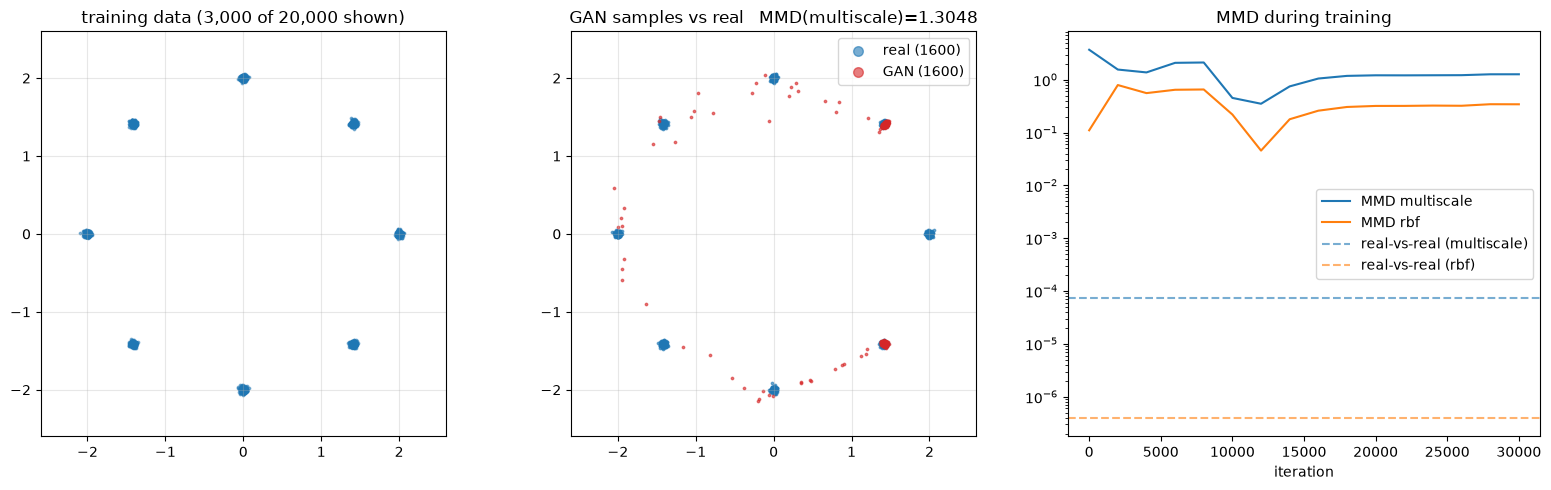

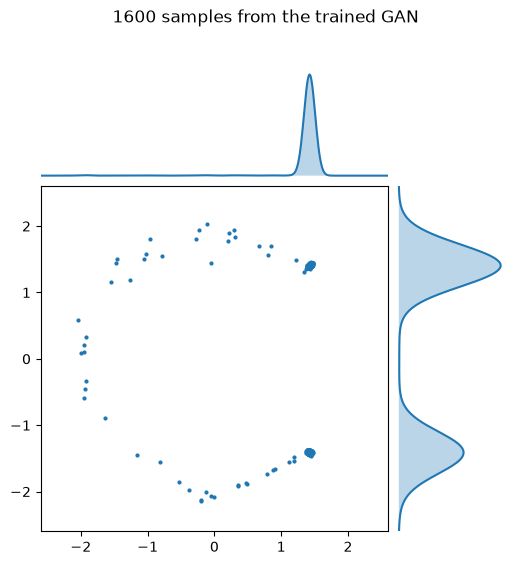

In [14]:
run_gan(["--seed", "0", "--iters", "30000", "--batch", "256", "--lr", "1e-4", "--eval_every", "2000", "--out_dir", "out_gan_vanilla30k"])

#### Vanilla GAN — shorter run (10,000 iterations), to show the training dynamics

it      1  lossD 1.413  lossG 0.692  MMD(ms) 3.69093  MMD(rbf) 0.110309  HQ 0.0%  modes 0/8
it   1000  lossD 1.084  lossG 0.956  MMD(ms) 1.94139  MMD(rbf) 0.747729  HQ 0.0%  modes 0/8
it   2000  lossD 1.125  lossG 1.081  MMD(ms) 1.55753  MMD(rbf) 0.792859  HQ 0.0%  modes 0/8
it   3000  lossD 1.140  lossG 1.079  MMD(ms) 1.37796  MMD(rbf) 0.640176  HQ 0.0%  modes 0/8
it   4000  lossD 0.908  lossG 1.262  MMD(ms) 1.37446  MMD(rbf) 0.557704  HQ 0.4%  modes 0/8
it   5000  lossD 0.929  lossG 1.312  MMD(ms) 1.85129  MMD(rbf) 0.772865  HQ 0.0%  modes 0/8
it   6000  lossD 0.845  lossG 1.380  MMD(ms) 2.08690  MMD(rbf) 0.645269  HQ 0.0%  modes 0/8
it   7000  lossD 0.736  lossG 1.508  MMD(ms) 2.14787  MMD(rbf) 0.747459  HQ 0.0%  modes 0/8
it   8000  lossD 0.596  lossG 1.602  MMD(ms) 2.11827  MMD(rbf) 0.653525  HQ 0.0%  modes 0/8
it   9000  lossD 0.568  lossG 1.836  MMD(ms) 2.05266  MMD(rbf) 0.836060  HQ 0.6%  modes 0/8
it  10000  lossD 0.762  lossG 1.327  MMD(ms) 0.45234  MMD(rbf) 0.219311  HQ 0.9%

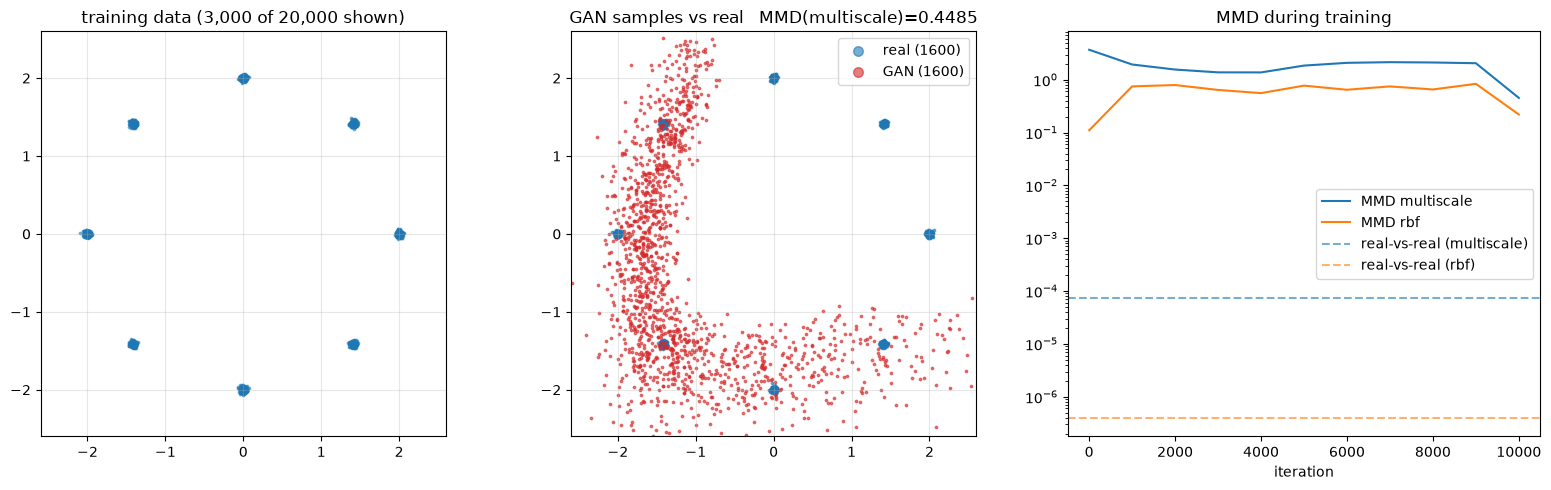

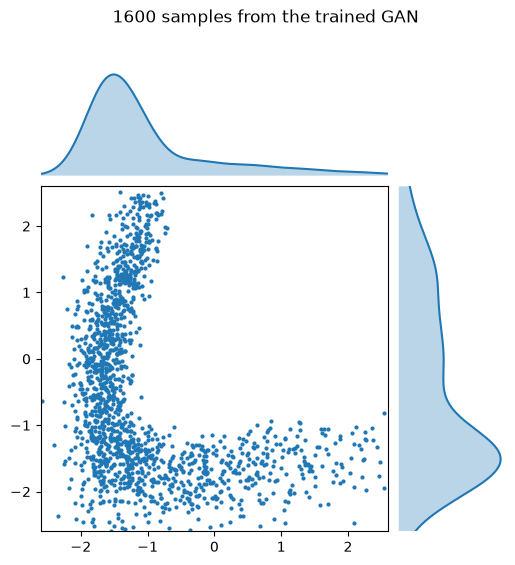

In [15]:
run_gan(["--seed", "0", "--iters", "10000", "--batch", "256", "--lr", "1e-4", "--eval_every", "1000", "--out_dir", "out_gan_v2"])

#### PacGAN (m = 4, same vanilla BCE loss) — 10,000 iterations, lr = 2e-4, batch 256

it      1  lossD 1.387  lossG 0.707  MMD(ms) 3.68729  MMD(rbf) 0.110204  HQ 0.0%  modes 0/8
it   1000  lossD 1.161  lossG 0.951  MMD(ms) 0.22970  MMD(rbf) 0.003450  HQ 0.3%  modes 0/8
it   2000  lossD 1.260  lossG 0.860  MMD(ms) 0.06280  MMD(rbf) 0.000291  HQ 9.9%  modes 2/8
it   3000  lossD 1.271  lossG 0.766  MMD(ms) 0.02037  MMD(rbf) 0.000748  HQ 35.8%  modes 8/8
it   4000  lossD 1.392  lossG 0.704  MMD(ms) 0.06644  MMD(rbf) 0.004984  HQ 9.6%  modes 2/8
it   5000  lossD 1.319  lossG 0.766  MMD(ms) 0.02104  MMD(rbf) 0.000027  HQ 37.8%  modes 8/8
it   6000  lossD 1.327  lossG 0.816  MMD(ms) 0.02438  MMD(rbf) 0.001295  HQ 39.2%  modes 8/8
it   7000  lossD 1.294  lossG 0.698  MMD(ms) 0.04146  MMD(rbf) 0.002661  HQ 22.7%  modes 6/8
it   8000  lossD 1.305  lossG 0.761  MMD(ms) 0.04105  MMD(rbf) 0.002637  HQ 18.9%  modes 6/8
it   9000  lossD 1.295  lossG 0.707  MMD(ms) 0.01649  MMD(rbf) 0.000489  HQ 54.9%  modes 8/8
it  10000  lossD 1.360  lossG 0.778  MMD(ms) 0.01212  MMD(rbf) 0.001014  H

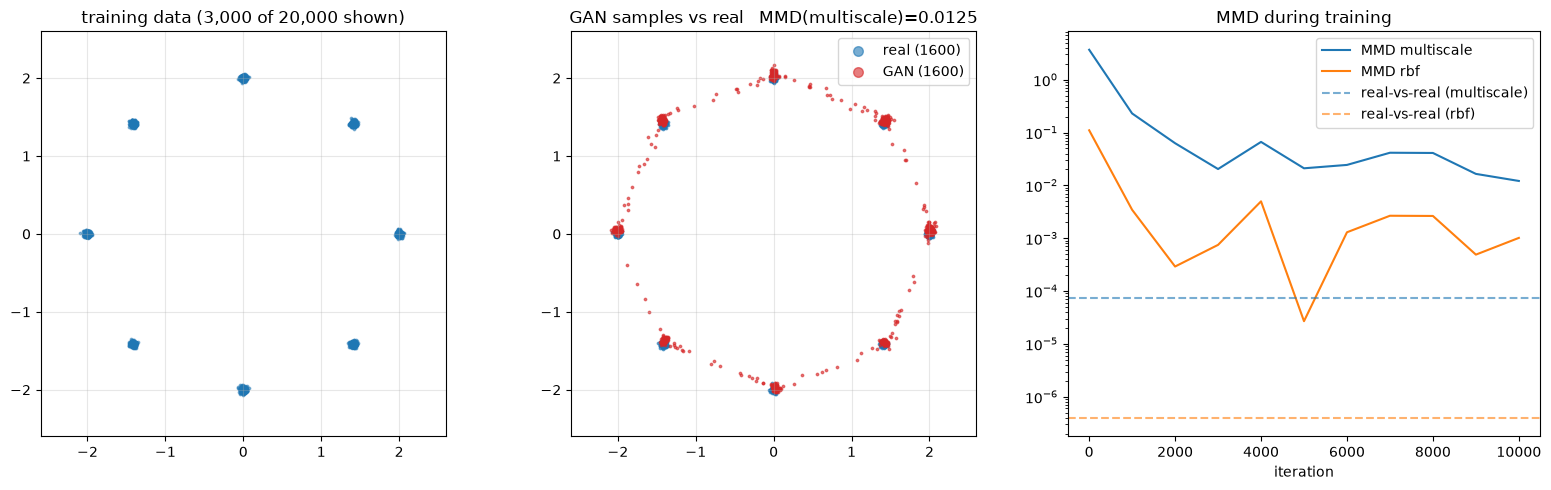

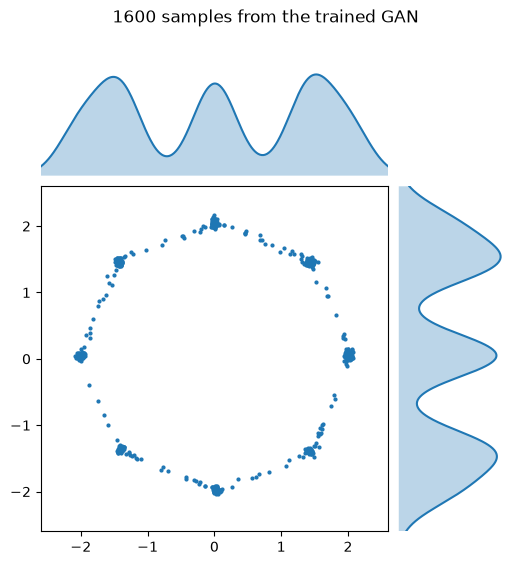

In [16]:
run_gan(["--seed", "0", "--iters", "10000", "--batch", "256", "--lr", "2e-4", "--pack", "4", "--eval_every", "1000", "--out_dir", "out_gan_pac4"])

#### Summary table of all GAN runs

In [17]:
rows = {}
for name, d in [("Vanilla GAN, 30k it.", "out_gan_vanilla30k"), ("Vanilla GAN, 10k it.", "out_gan_v2"),
                ("PacGAN m=4, 10k it.", "out_gan_pac4")]:
    r = json.load(open(f"{d}/results.json"))
    rows[name] = {"MMD multiscale": r["MMD_multiscale_gen_vs_real"], "MMD rbf": r["MMD_rbf_gen_vs_real"],
                  "% within 3 sigma": 100 * r["gen_frac_high_quality"], "modes covered (of 8)": r["gen_modes_covered"],
                  "HQ samples per mode": r["gen_hq_counts_per_mode"]}
    
ms = mode_stats(sample_balanced(200, np.random.default_rng(10_000), 2.0), 2.0)   # same real set as in the runs
rows["Real vs real (floor)"] = {"MMD multiscale": r["MMD_multiscale_real_vs_real"], "MMD rbf": r["MMD_rbf_real_vs_real"],
                                "% within 3 sigma": 100 * ms["frac_high_quality"], "modes covered (of 8)": ms["modes_covered"],
                                "HQ samples per mode": ms["hq_counts_per_mode"]}

summary = pd.DataFrame(rows).T
summary

,MMD multiscale,MMD rbf,% within 3 sigma,modes covered (of 8),HQ samples per mode
"Vanilla GAN, 30k it.",1.30482,0.356764,96.5625,2,"[0, 943, 0, 0, 0, 0, 0, 602]"
"Vanilla GAN, 10k it.",0.448456,0.218357,0.875,0,"[0, 0, 0, 5, 0, 9, 0, 0]"
"PacGAN m=4, 10k it.",0.012491,0.000387,67.0625,8,"[127, 117, 125, 128, 138, 105, 163, 170]"
Real vs real (floor),0.000074,0.0,99.0,8,"[199, 200, 198, 194, 198, 198, 197, 200]"


### Results and discussion — Problem 2: how good are these results?

**MMD to report.** 1,600 generated samples vs. 1,600 real samples (200 from each of the 8 normals, independent random stream):

| Model | MMD (multiscale) | MMD (rbf) | % within 3σ of a centre | Modes covered | HQ samples per mode |
|---|---|---|---|---|---|
| Real vs real (noise floor) | 7.4·10⁻⁵ | 3.9·10⁻⁷ | 99.0 % | 8/8 | 194–200 |
| **Vanilla GAN, 30k iterations** | **1.305** | **0.357** | 96.6 % | **2/8** | [0, 943, 0, 0, 0, 0, 0, 602] |
| Vanilla GAN, 10k iterations | 0.448 | 0.218 | 0.9 % | 0/8 | [0, 0, 0, 5, 0, 9, 0, 0] |
| PacGAN m = 4, 10k iterations | **0.0125** | **3.9·10⁻⁴** | 67.1 % | **8/8** | 105–170 |

(The 99.0 % for real samples is a sanity check: for a 2-D isotropic Gaussian, $P(\|x-\mu\|<3\sigma) = 1-e^{-9/2} \approx 0.989$)

**1. The vanilla GAN does not learn this distribution.** Its training goes through two phases:
* *Diffuse phase* (up to ≈ 10k iterations). The generator puts its mass in a wide region covering the left and bottom of the circle (sample mean (−0.99, −0.46), std of the radius 0.44 vs. 0.02 for real data). Almost no sample (0.9 %) lands within 3σ of a centre, and no mode is covered.
* *Mode-collapse phase* (from ≈ 12k iterations). The generator suddenly sharpens: at 30k iterations 96.6 % of the samples are within 3σ of a centre, which looks very good, but **all of them lie in just 2 of the 8 modes** (the ones at 45° and 315°; 943 and 602 samples). The few remaining points are spread along the circle between modes.

Training longer does not fix this. The best vanilla snapshot is at 12k iterations (MMD 0.351, 2 modes). After that the multiscale MMD *increases* steadily to 1.305 at 30k: the samples become sharper but less diverse, and the MMD (correctly) penalizes the missing modes more than it rewards the sharpness.

**2. Why this problem is hard for a vanilla GAN.**
* The modes are extremely narrow: σ = 0.02, while neighbouring centres are ≈ 1.53 apart (2·2·sin(π/8)).
* $G$ maps a connected latent space (a Gaussian) through a continuous network. Covering 8 disconnected, tiny blobs therefore requires an almost discontinuous map, so some mass is inevitably left between the modes.
* The vanilla objective gives the generator no direct incentive to be *diverse*. $D$ judges one sample at a time, so a generator that only produces two perfect modes is not penalized for the six it ignores. $G$ can lower its loss by moving its mass onto whichever modes $D$ currently classifies as most "real": that is mode collapse.

**3. PacGAN fixes most of the problem without changing the loss.** The discriminator judges 4 samples jointly, so a collapsed generator (whose 4 samples look alike) is easy to detect. Results at 10k iterations:
* all **8/8 modes** are covered, with a fairly balanced allocation (105–170 high-quality samples per mode, against 134 if perfectly balanced);
* the multiscale MMD is **0.0125**: about **104× lower** than the 30k vanilla run (1.305), **36×** lower than the 10k vanilla run, and **28×** lower than the best vanilla snapshot (0.351).

Training is not fully stable, though. Coverage drops temporarily to 2/8 at 4k iterations and to 6/8 at 7k–8k before recovering, and the MMD curve oscillates rather than decreasing monotonically.

PacGAN is still about **170×** above the real-vs-real noise floor in multiscale MMD (≈ 1,000× in rbf). Two reasons explain the gap, both visible in the scatter plot:
* a fraction of samples form "bridges" along the circle between neighbouring modes;
* the modes are wider than σ = 0.02 (std of the radius 0.045), so only 67 % of the samples are within 3σ, against 99 % for real data.

**4. On the MMD as a metric.**
* The **rbf** kernel of the referenced notebook uses $\exp(-\|x-y\|^2 / (2a))$ with $a \in \{10, 15, 20, 50\}$, i.e. length scales of ≈ 3–7, larger than the diameter of the whole mixture (4). It mostly compares the overall location and spread of the two samples and is nearly blind to the 8-mode structure. Clear evidence: the **untrained** generator at iteration 1 (a blob near the origin, which is the mixture mean) gets rbf MMD = 0.110, *better* than both trained vanilla GANs (0.218 and 0.357), even though it covers no mode at all.
* The **multiscale** kernel (bandwidths 0.2–1.3) is much more informative here. It gives the untrained generator the worst score (3.69) and ranks the final models correctly: PacGAN (0.0125) < vanilla 10k (0.448) < vanilla 30k (1.305).
* Even so, both kernels are much wider than σ = 0.02, so neither fully resolves *within-mode* quality. This is why we complement the MMD with the real-vs-real baseline and the mode statistics. Together they give an interpretable answer to "how good are these results?".

**Conclusion.**
* The vanilla GAN does not reproduce the distribution: after 30k iterations it collapses to 2 of 8 modes, with MMD (multiscale) = **1.305** against a noise floor of 7.4·10⁻⁵.
* A minimal modification that keeps the vanilla BCE objective (PacGAN, m = 4) produces samples that look like Figure 1, covering all 8 modes with MMD (multiscale) = **0.0125** and MMD (rbf) = **3.9·10⁻⁴**. It is still about two orders of magnitude above the noise floor, so there is measurable room for improvement: sharper modes and fewer between-mode samples.
